In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df= pd.read_csv('winequality-red.csv')
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
df.tail()


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [5]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(240)

In [7]:
df=df.drop_duplicates()

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')

### Univariate Analysis

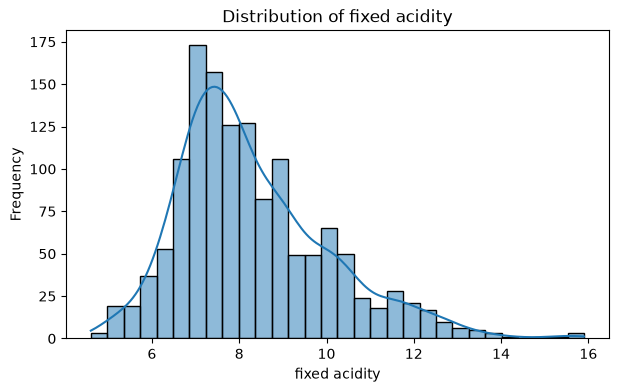

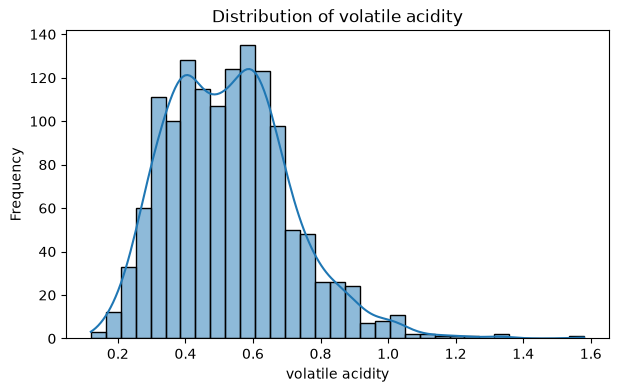

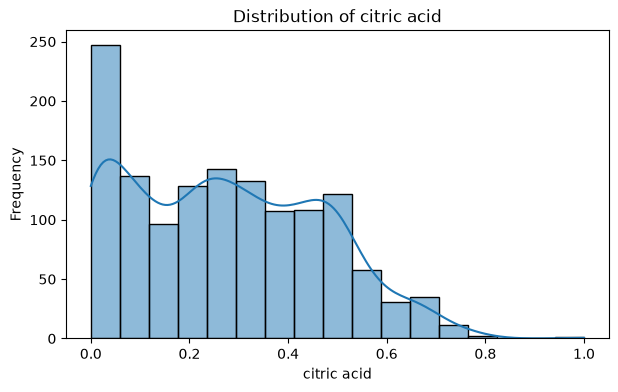

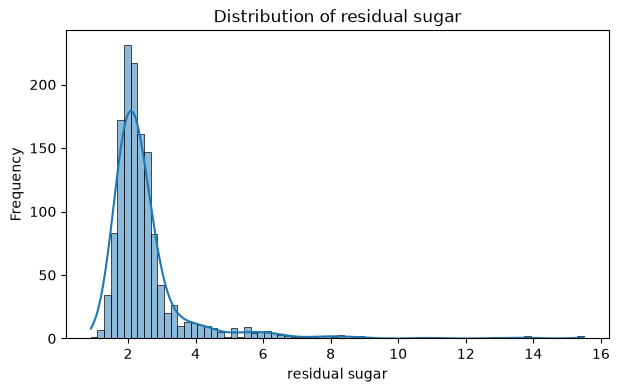

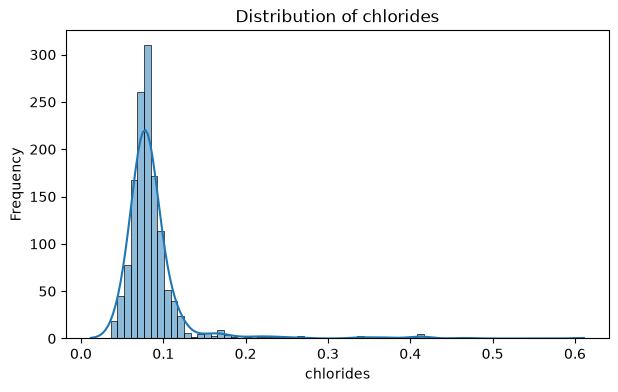

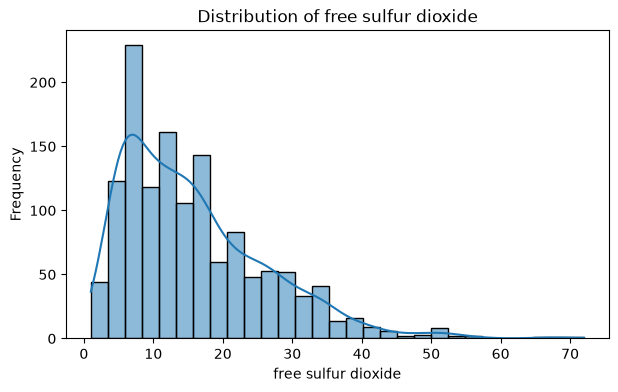

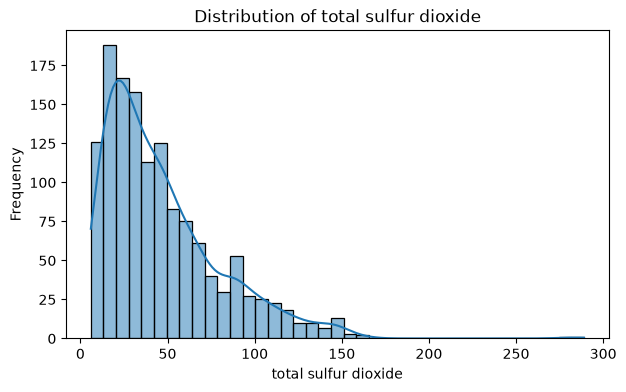

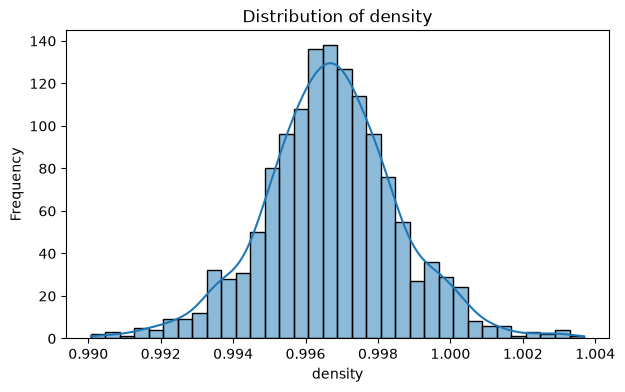

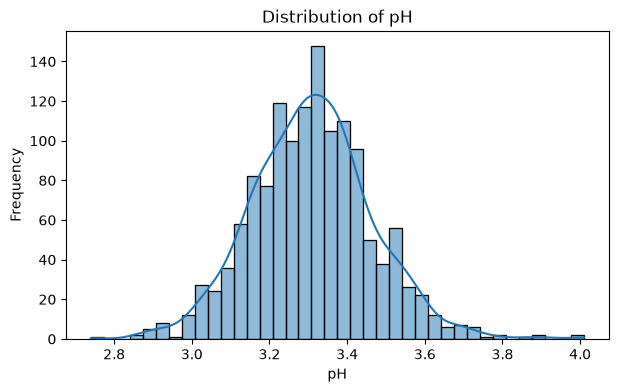

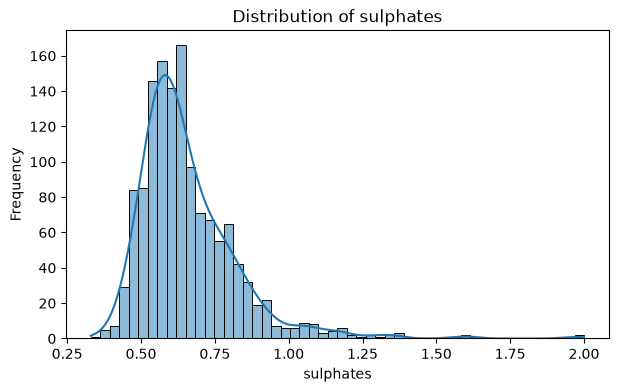

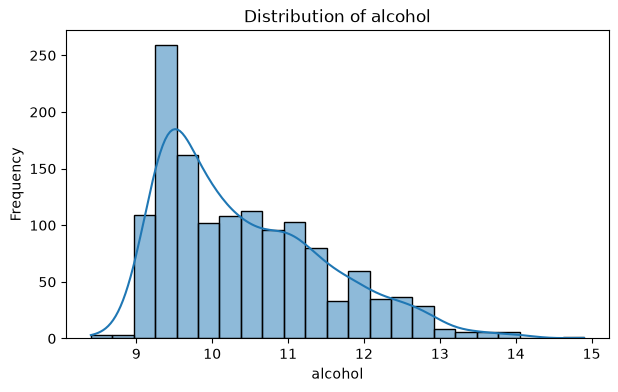

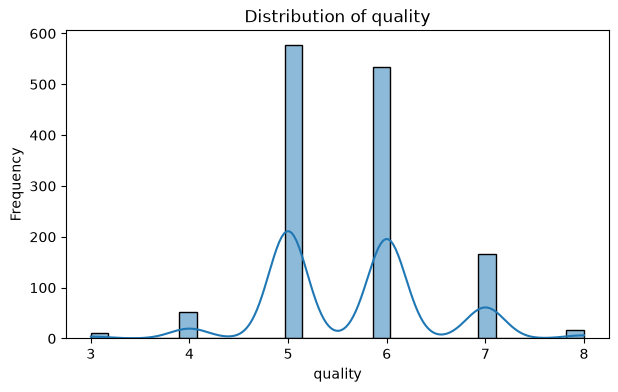

In [10]:
# +kde
numeric_cols=df.columns
for col in numeric_cols:
    plt.figure(figsize=(7,4))
    sns.histplot(df[col],kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

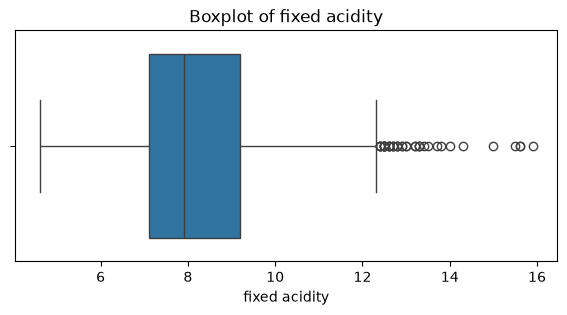

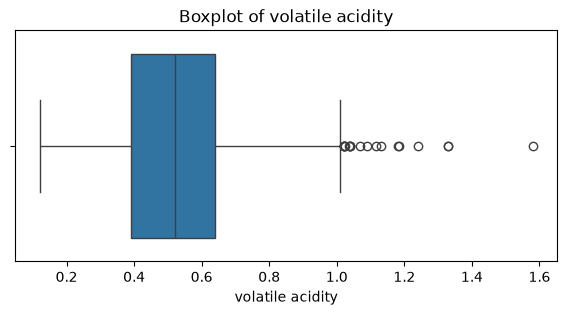

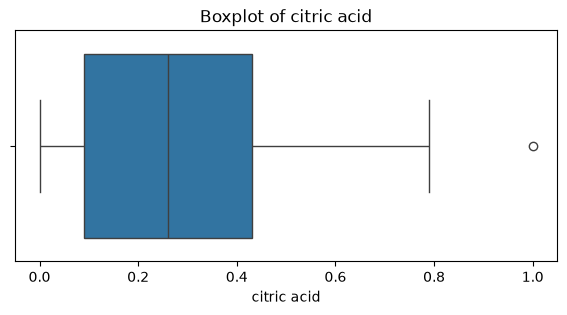

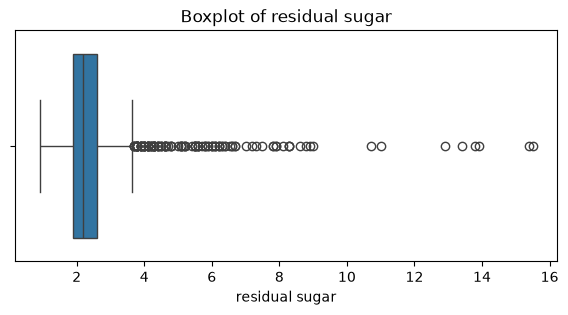

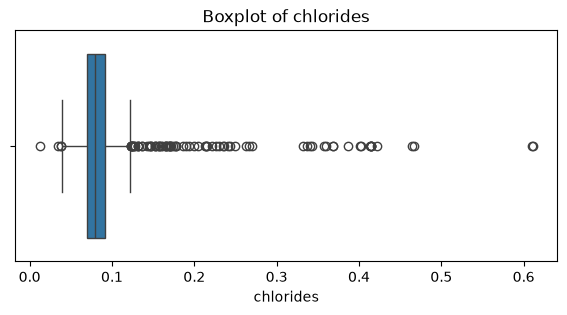

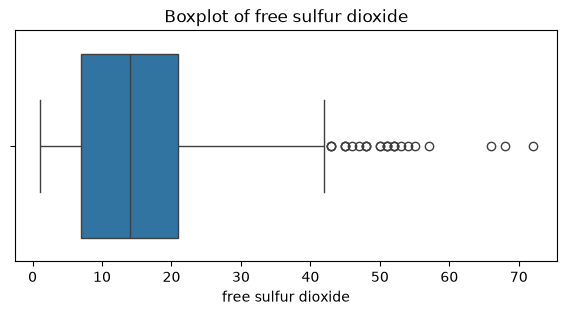

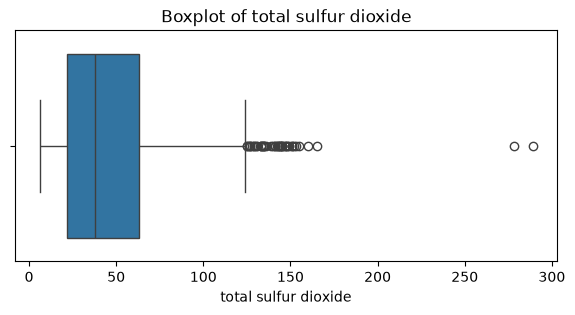

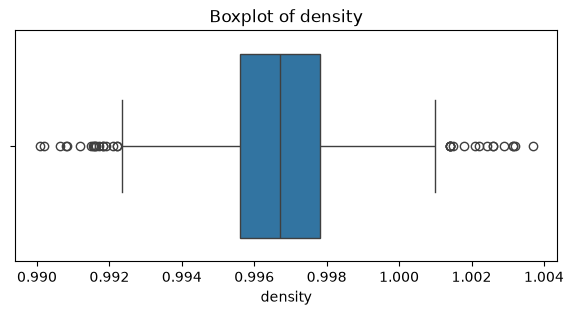

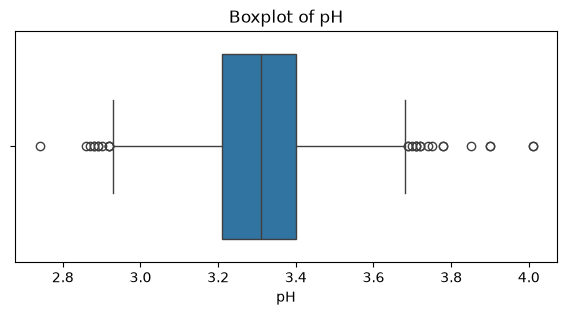

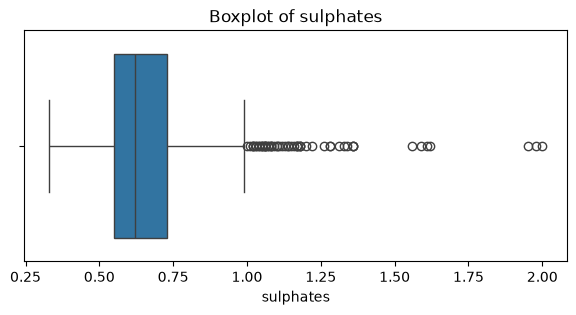

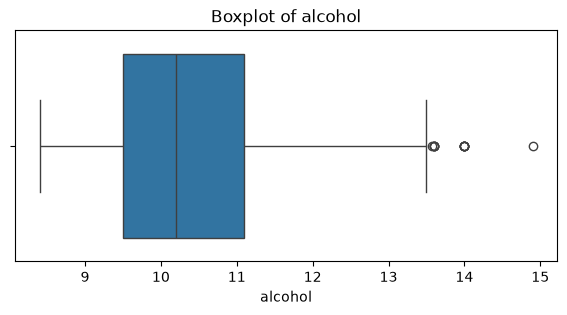

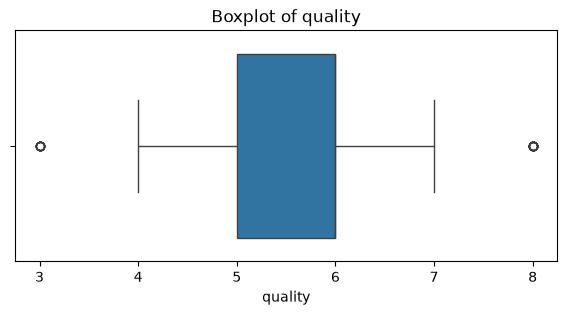

In [11]:
#Box_plot -Outlier Detection
for col in numeric_cols:
    plt.figure(figsize=(7,3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [12]:
#detect outliers for every feature
features=df.drop(columns=['quality'])

Q1=features.quantile(0.25)
Q2=features.quantile(0.75)

IQR=Q2-Q1

lower_bound=Q1-1.5 *IQR
upper_bound=Q2+1.5 *IQR

outlier_mask=(features < lower_bound )| (features > upper_bound)

outlier_count=outlier_mask.sum()

outlier_percentage=(outlier_count / len(features)) *100

outlier_summary=pd.DataFrame({
    'Q1' :Q1,
    'Q2':Q2,
    'IQR':IQR,
    'Lower Bound':lower_bound,
    'Upper Bound':upper_bound,
    'Outlier Count':outlier_count,
    'Outlier %': outlier_percentage
})

outlier_summary.round(3)

,Q1,Q2,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
fixed acidity,7.100,9.200,2.100,3.950,12.350,41,3.017
volatile acidity,0.390,0.640,0.250,0.015,1.015,19,1.398
citric acid,0.090,0.430,0.340,-0.420,0.940,1,0.074
residual sugar,1.900,2.600,0.700,0.850,3.650,126,9.272
chlorides,0.070,0.091,0.021,0.039,0.122,87,6.402
free sulfur dioxide,7.000,21.000,14.000,-14.000,42.000,26,1.913
total sulfur dioxide,22.000,63.000,41.000,-39.500,124.500,45,3.311
density,0.996,0.998,0.002,0.992,1.001,35,2.575
pH,3.210,3.400,0.190,2.925,3.685,28,2.060
sulphates,0.550,0.730,0.180,0.280,1.000,55,4.047


In [13]:
# Number of outliers in each feature

print("Outliers in each feature \n")
for column in features.columns:
    print(f"{column:25s}:{outlier_count[column]}")

Outliers in each feature 

fixed acidity            :41
volatile acidity         :19
citric acid              :1
residual sugar           :126
chlorides                :87
free sulfur dioxide      :26
total sulfur dioxide     :45
density                  :35
pH                       :28
sulphates                :55
alcohol                  :12


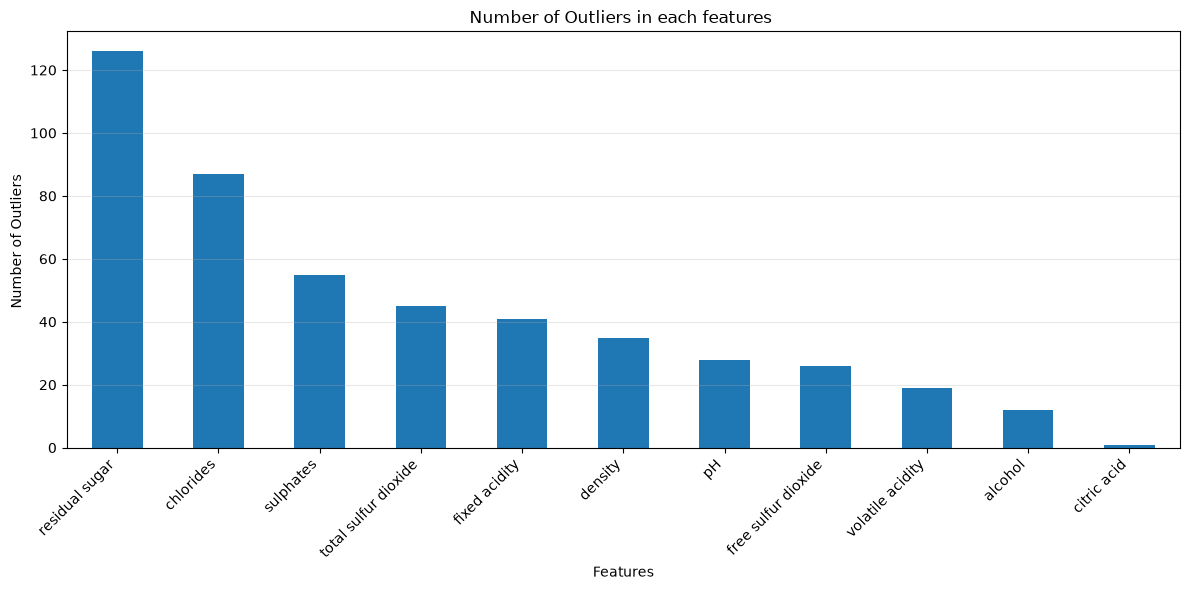

In [14]:
plt.figure(figsize=(12,6))

outlier_count.sort_values(ascending=False).plot(
    kind='bar'
)

plt.title("Number of Outliers in each features ")
plt.xlabel('Features')
plt.ylabel('Number of Outliers ')
plt.xticks(rotation=45,ha='right')
plt.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.show()

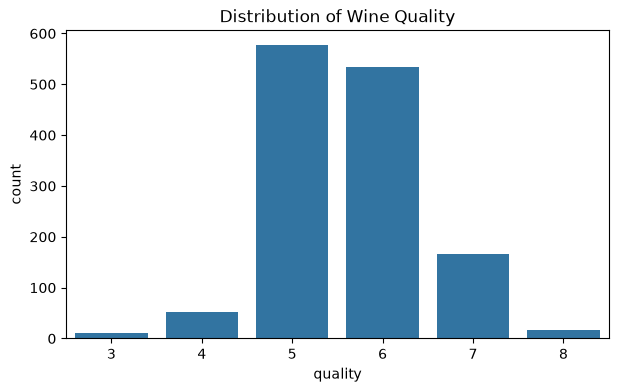

In [15]:
#Quality Distribution

plt.figure(figsize=(7,4))
sns.countplot(x='quality',data=df)
plt.title('Distribution of Wine Quality')
plt.show()

In [16]:
df['quality'].value_counts().sort_index()

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64

###  2. Bivariate Analysis

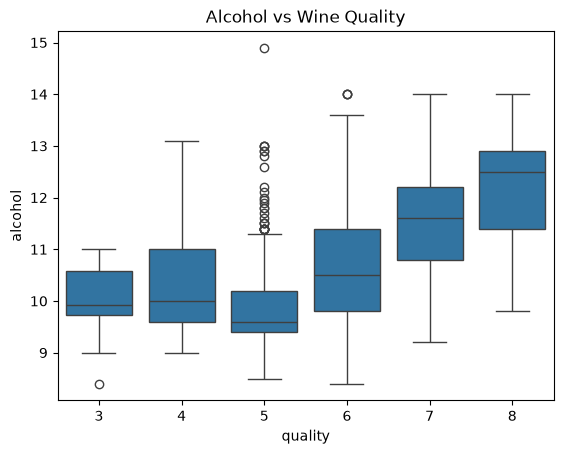

In [17]:
#Alcohol vs Quality

sns.boxplot(x='quality', y='alcohol', data=df)
plt.title('Alcohol vs Wine Quality')
plt.show()

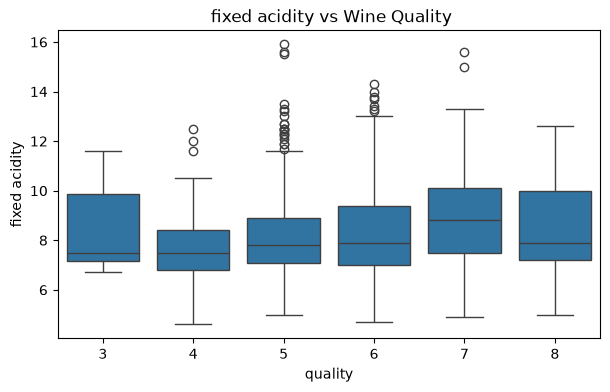

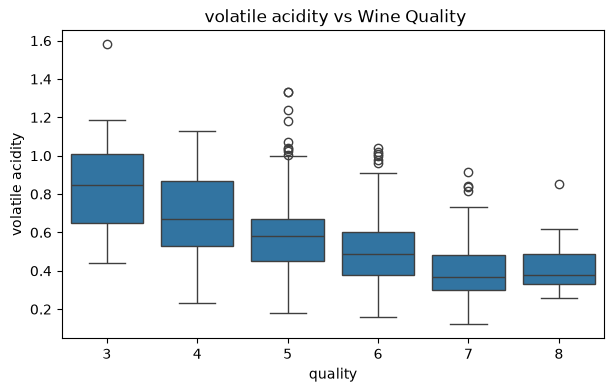

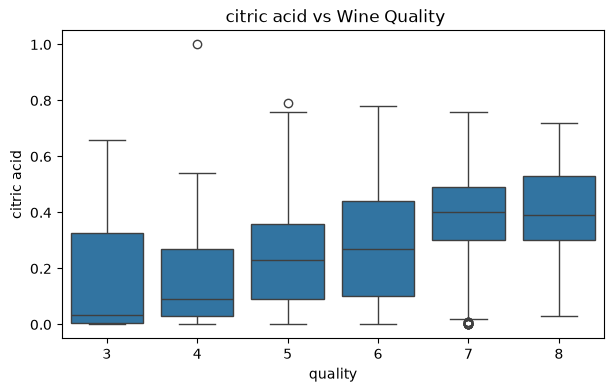

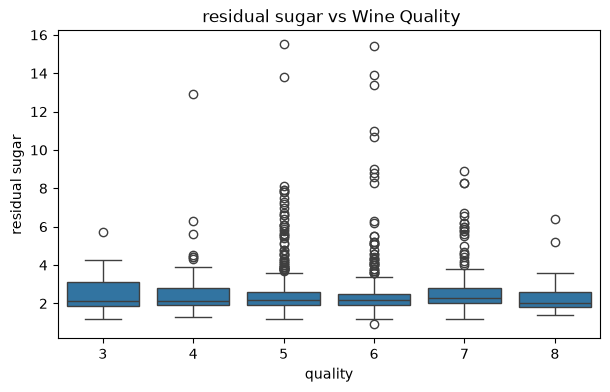

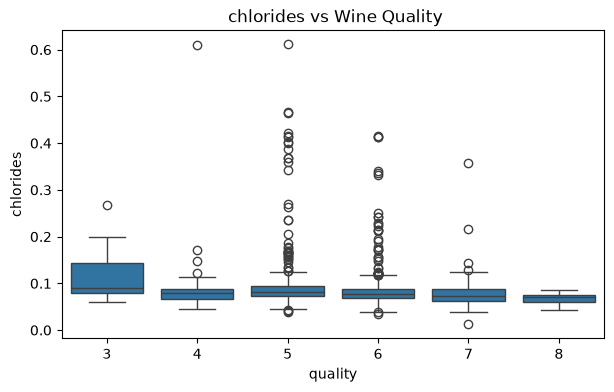

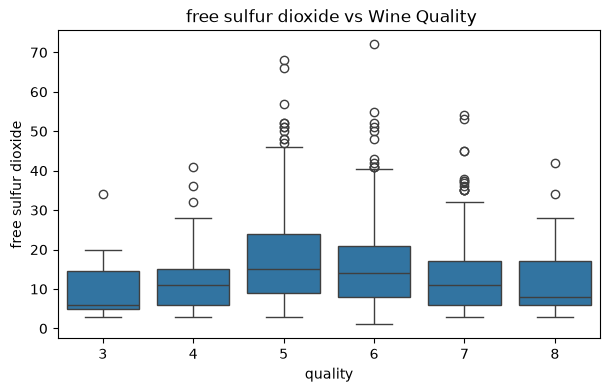

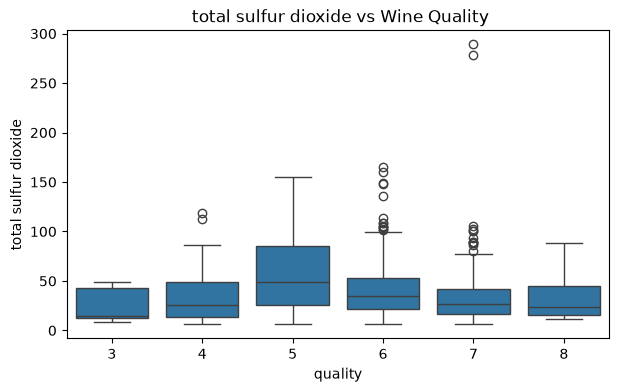

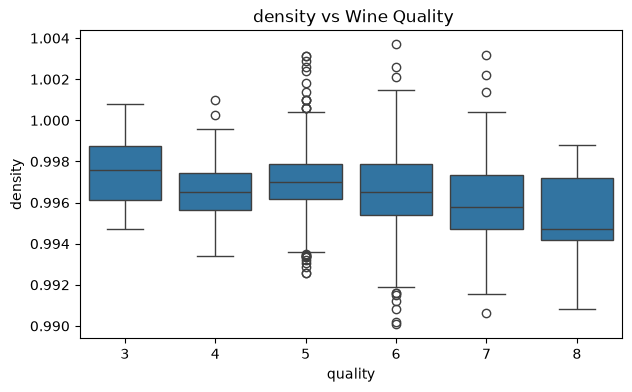

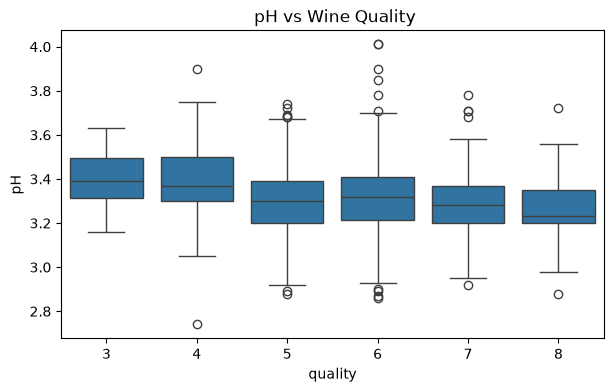

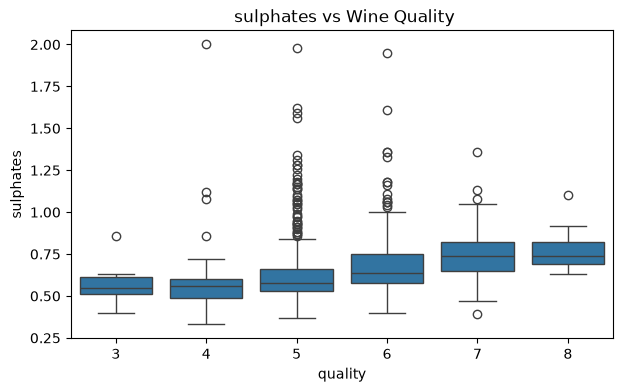

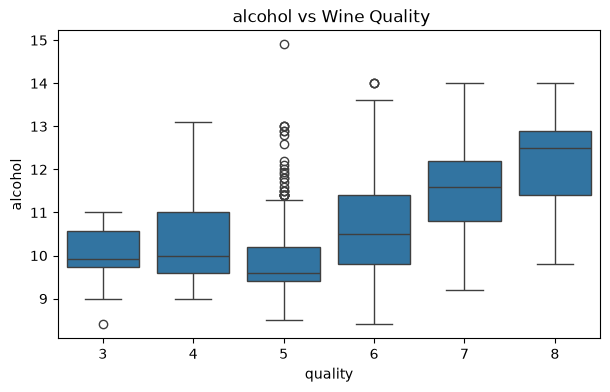

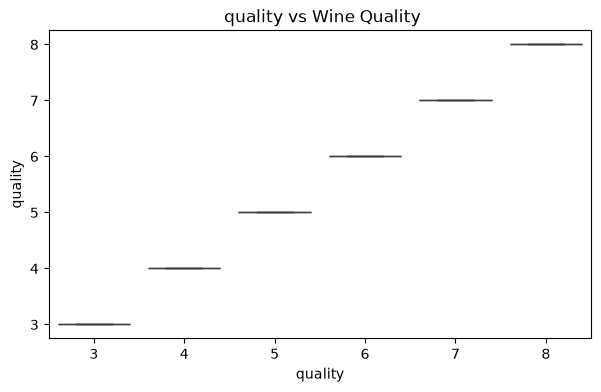

In [18]:
features=['fixed acidity',	'volatile acidity',	'citric acid',	'residual sugar',
          'chlorides',	'free sulfur dioxide',	'total sulfur dioxide'	,
          'density'	,'pH', 'sulphates' ,'alcohol',	'quality']
for col in features:
    plt.figure(figsize=(7,4))
    sns.boxplot(x='quality', y=col, data=df)
    plt.title(f' {col} vs Wine Quality')
    plt.show()

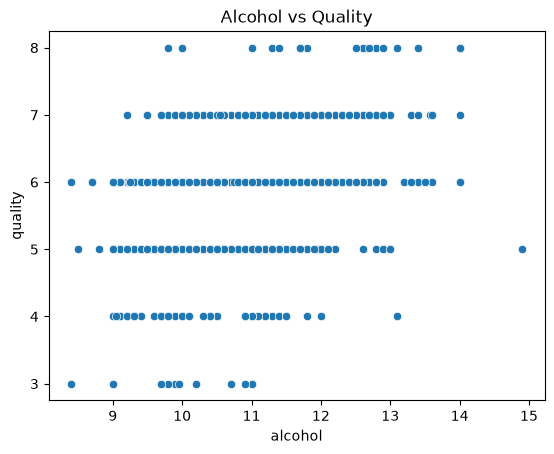

In [19]:
# scatter plot
sns.scatterplot(x='alcohol',y='quality', data=df)
plt.title('Alcohol vs Quality')
plt.show()

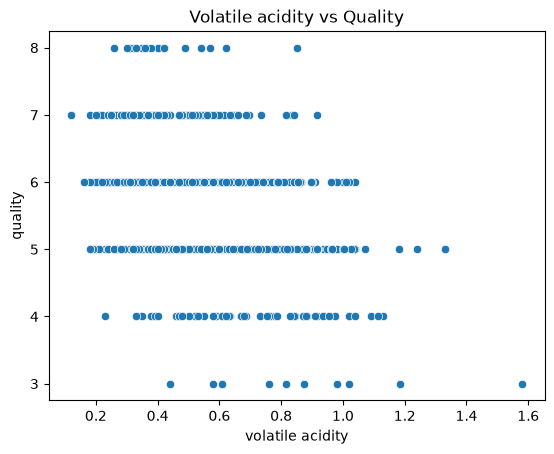

In [20]:
sns.scatterplot(x='volatile acidity',y='quality', data=df)
plt.title('Volatile acidity vs Quality')
plt.show()

### v3. Multivariate Analysis

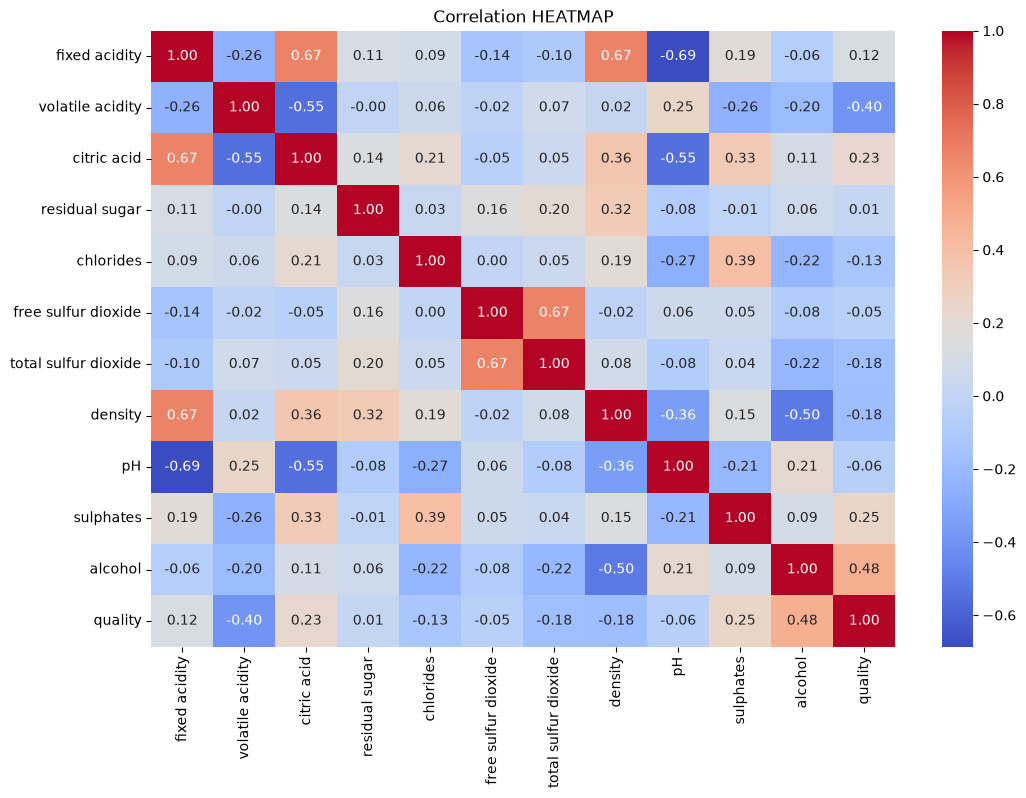

In [21]:
plt.figure(figsize=(12,8))
corr=df.corr()

sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f')
plt.title("Correlation HEATMAP")
plt.show()

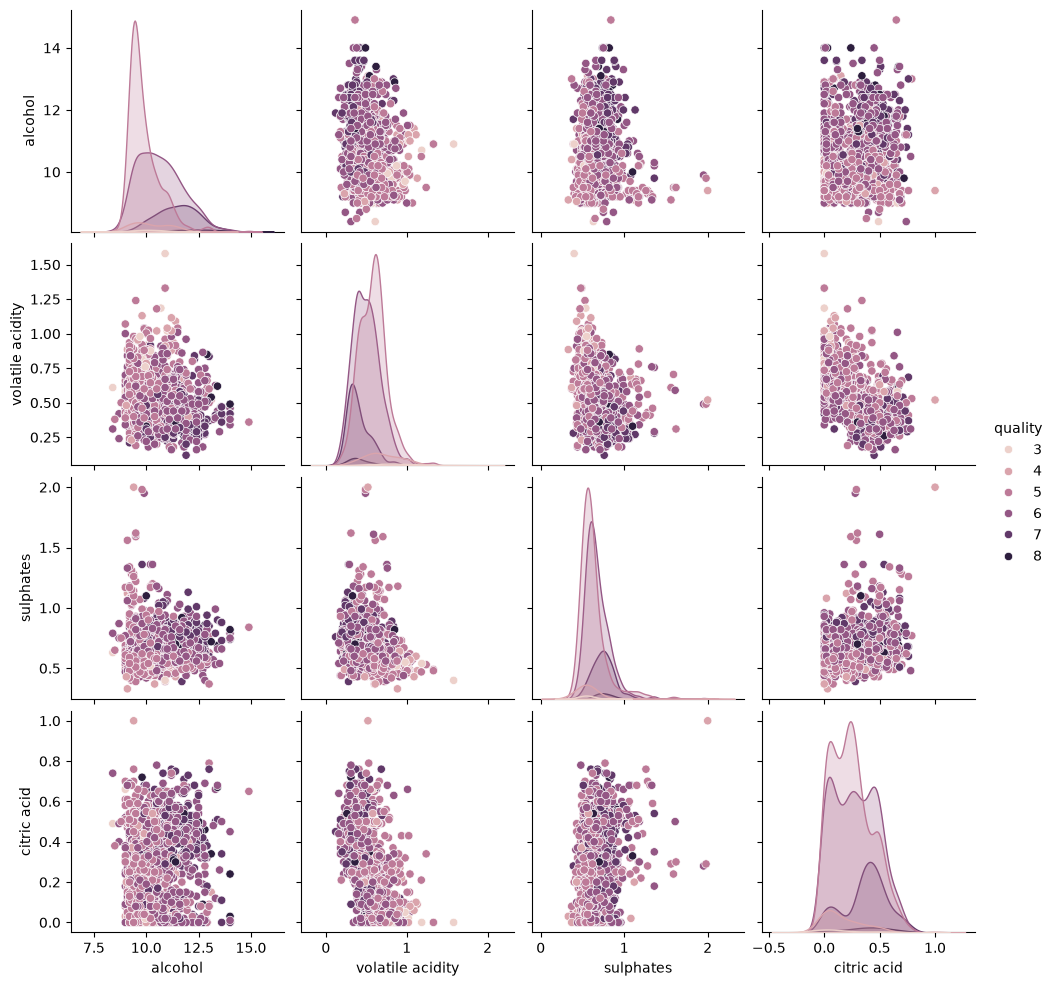

In [22]:
# pair plot
selected=['alcohol','volatile acidity','sulphates','citric acid','quality']
sns.pairplot(df[selected],hue='quality')
plt.show()

In [23]:
# multivariate analysis using Quality Groups
df['quality_group']=pd.cut(df['quality'], bins=[0,5,6,10],labels=['Low','Medium','High']
)

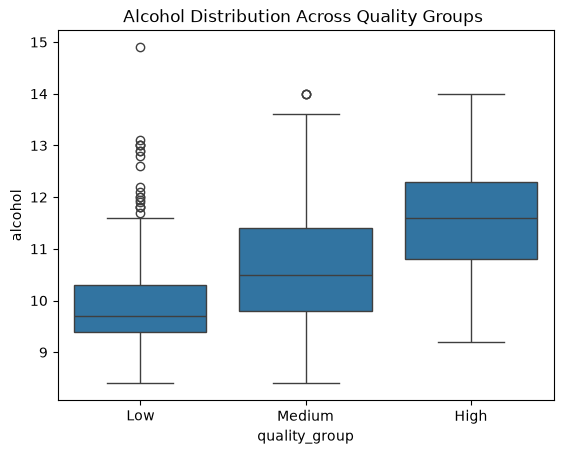

In [24]:
sns.boxplot(x='quality_group',y='alcohol',data=df)
plt.title('Alcohol Distribution Across Quality Groups ')
plt.show()

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,classification_report,
                            confusion_matrix,ConfusionMatrixDisplay)

In [26]:
X=df.drop('quality',axis=1)
y=df['quality']
print("X shape ",X.shape)
print("y shape ",y.shape)

X shape  (1359, 12)
y shape  (1359,)


In [27]:
print(y.value_counts().sort_index())

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


In [28]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)


In [29]:
criterion='entropy'
dt_model=DecisionTreeClassifier(criterion='entropy',random_state=42)

In [30]:
df['quality_group']=pd.cut(df['quality'], bins=[0,5,6,10],labels=['Low','Medium','High']
)

In [31]:
print(X.columns)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality_group'],
      dtype='str')


In [32]:
print(X.select_dtypes(exclude='number').columns)

Index(['quality_group'], dtype='str')


In [33]:
y=df['quality']
X=df.drop(columns=['quality','quality_group'],errors='ignore')

In [34]:
print(X.columns)
print(X.dtypes)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol'],
      dtype='str')
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
dtype: object


In [35]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [36]:
print(X_train,X_test,y_train,y_test)

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
748             7.2              0.50         0.18             2.1      0.071   
1257            7.0              0.58         0.28             4.8      0.085   
16              8.5              0.28         0.56             1.8      0.092   
779             7.1              0.52         0.03             2.6      0.076   
792             7.1              0.61         0.02             2.5      0.081   
...             ...               ...          ...             ...        ...   
1216            7.9              0.57         0.31             2.0      0.079   
241            12.0              0.38         0.56             2.1      0.093   
1276            8.5              0.40         0.40             6.3      0.050   
1516            6.1              0.32         0.25             2.3      0.071   
1135            8.0              0.25         0.43             1.7      0.067   

      free sulfur dioxide  

In [37]:
dt_model=DecisionTreeClassifier(criterion='entropy',random_state=42)
dt_model.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

In [38]:
y_train_pred=dt_model.predict(X_train)
y_test_pred=dt_model.predict(X_test)

In [39]:
train_accuracy=accuracy_score(y_train,y_train_pred)
print("Training Accuracy: ",train_accuracy)

Training Accuracy:  1.0


In [40]:
test_accuracy=accuracy_score(y_test,y_test_pred)
print(test_accuracy)

0.4963235294117647


In [41]:
print("precision:",
       precision_score(y_test, y_test_pred, average='weighted'))
print("Recall:",
      recall_score(y_test, y_test_pred, average='weighted'))
print("F1 Score:",
      f1_score(y_test, y_test_pred, average='weighted'))

precision: 0.49434982217769985
Recall: 0.4963235294117647
F1 Score: 0.4951045941835992


C:\Users\Yash\scoop\apps\python\current\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


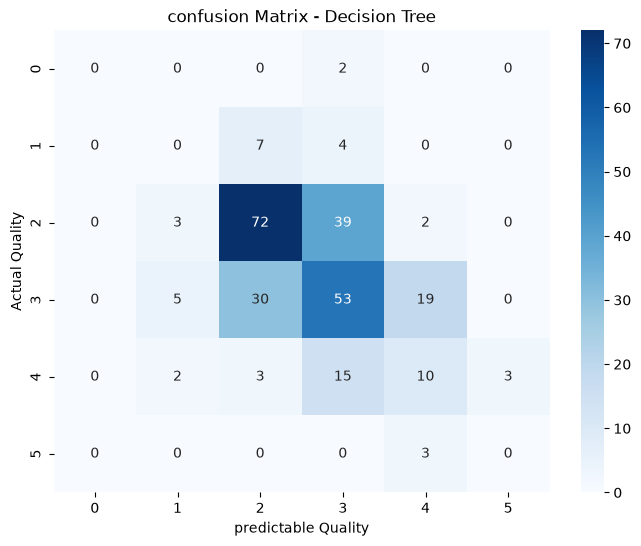

In [42]:
# confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(8,6))

sns.heatmap(cm, annot=True, fmt='d' , cmap='Blues')

plt.xlabel('predictable Quality')
plt.ylabel('Actual Quality')
plt.title('confusion Matrix - Decision Tree')
plt.show()

In [43]:
print("Tree Depth: ",dt_model.get_depth())
print("Number of leaves: ",dt_model.get_n_leaves())

Tree Depth:  18
Number of leaves:  299


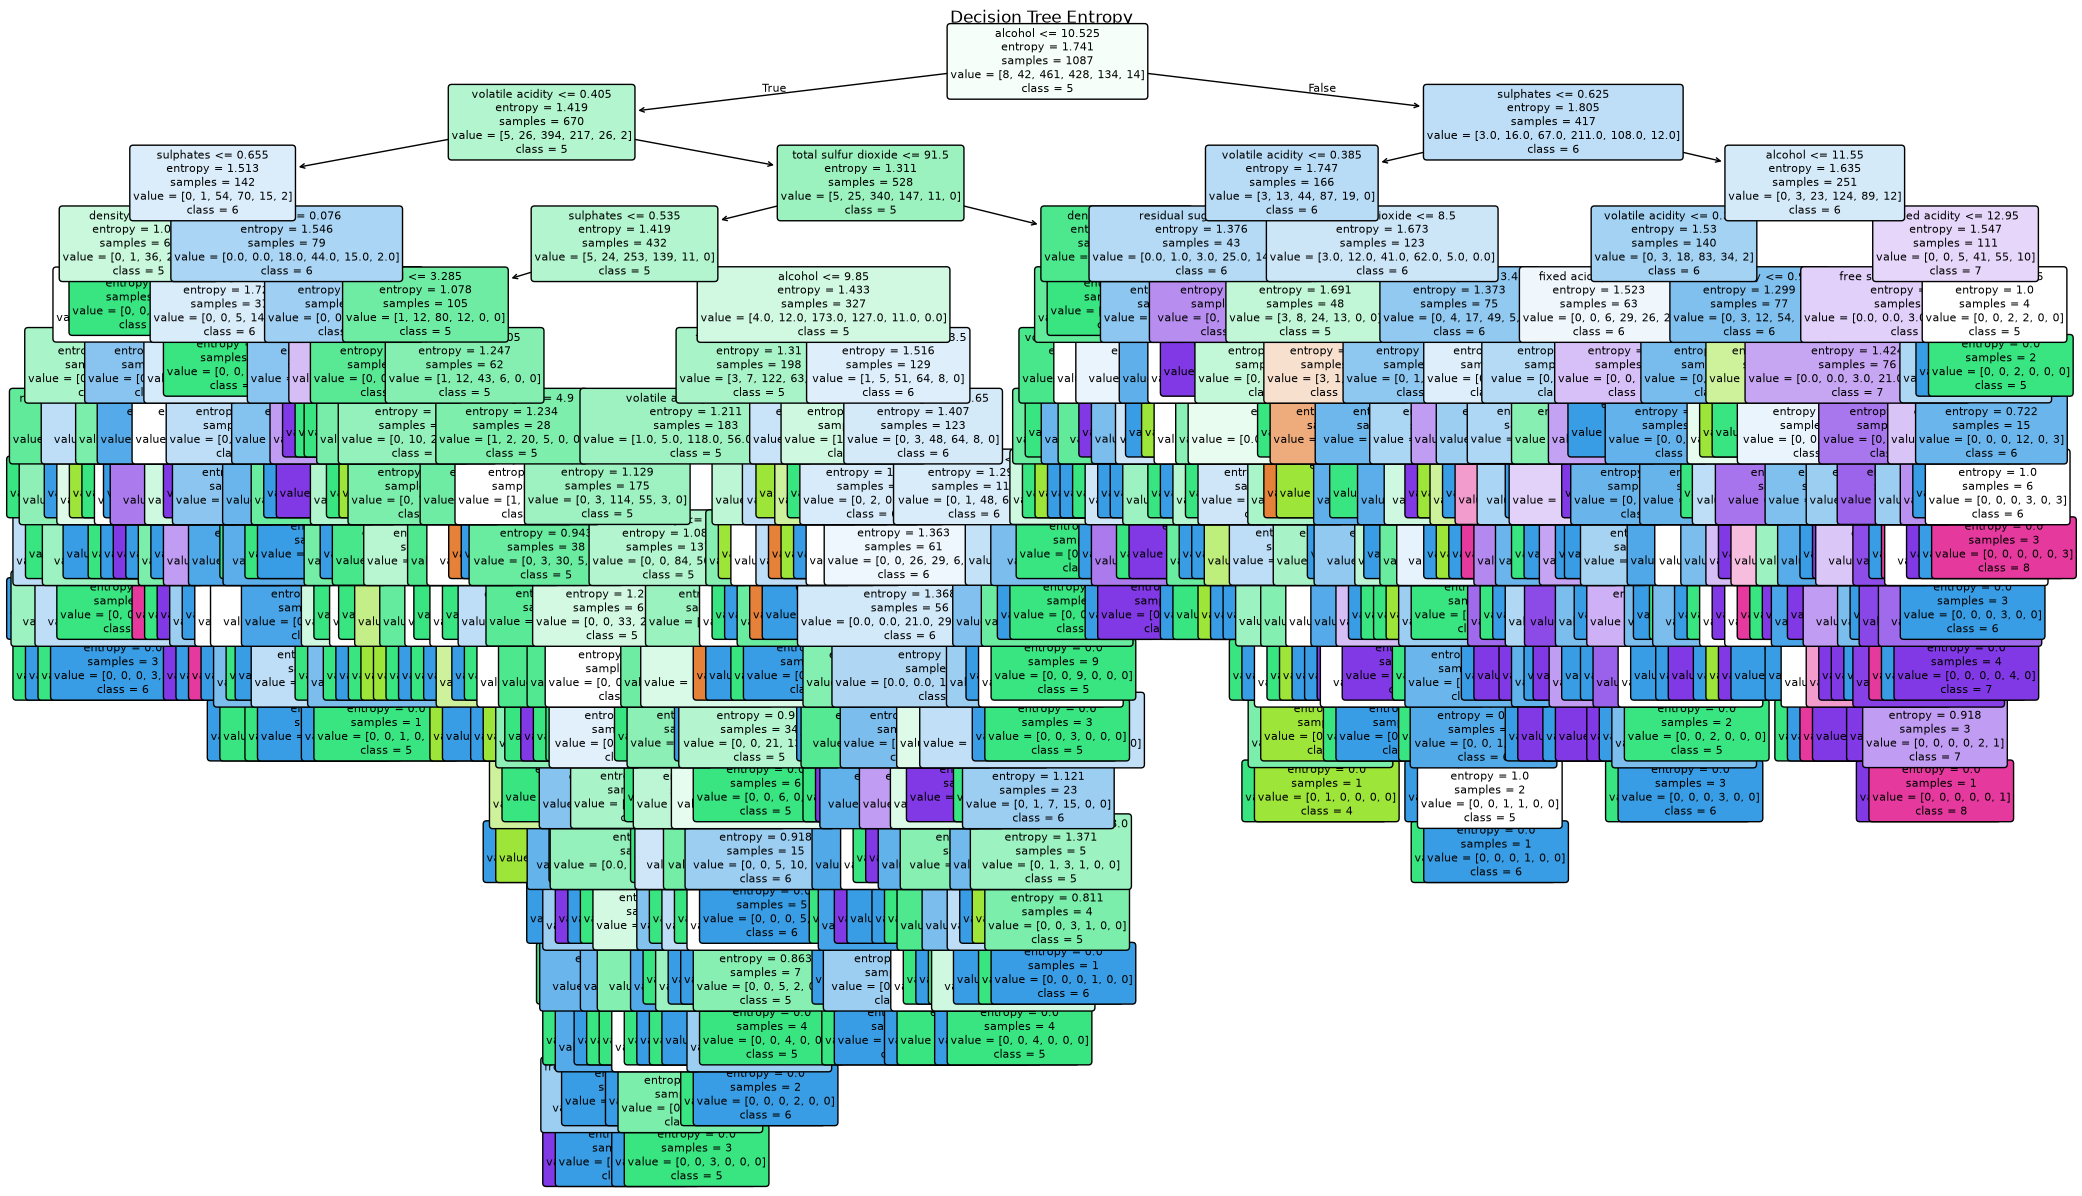

In [44]:
plt.figure(figsize=(25,15))
plot_tree(dt_model,feature_names=X.columns,
          class_names=[str(c) for c in sorted(y.unique())],
          filled=True,rounded=True,fontsize=8)

plt.title("Decision Tree Entropy")
plt.show()

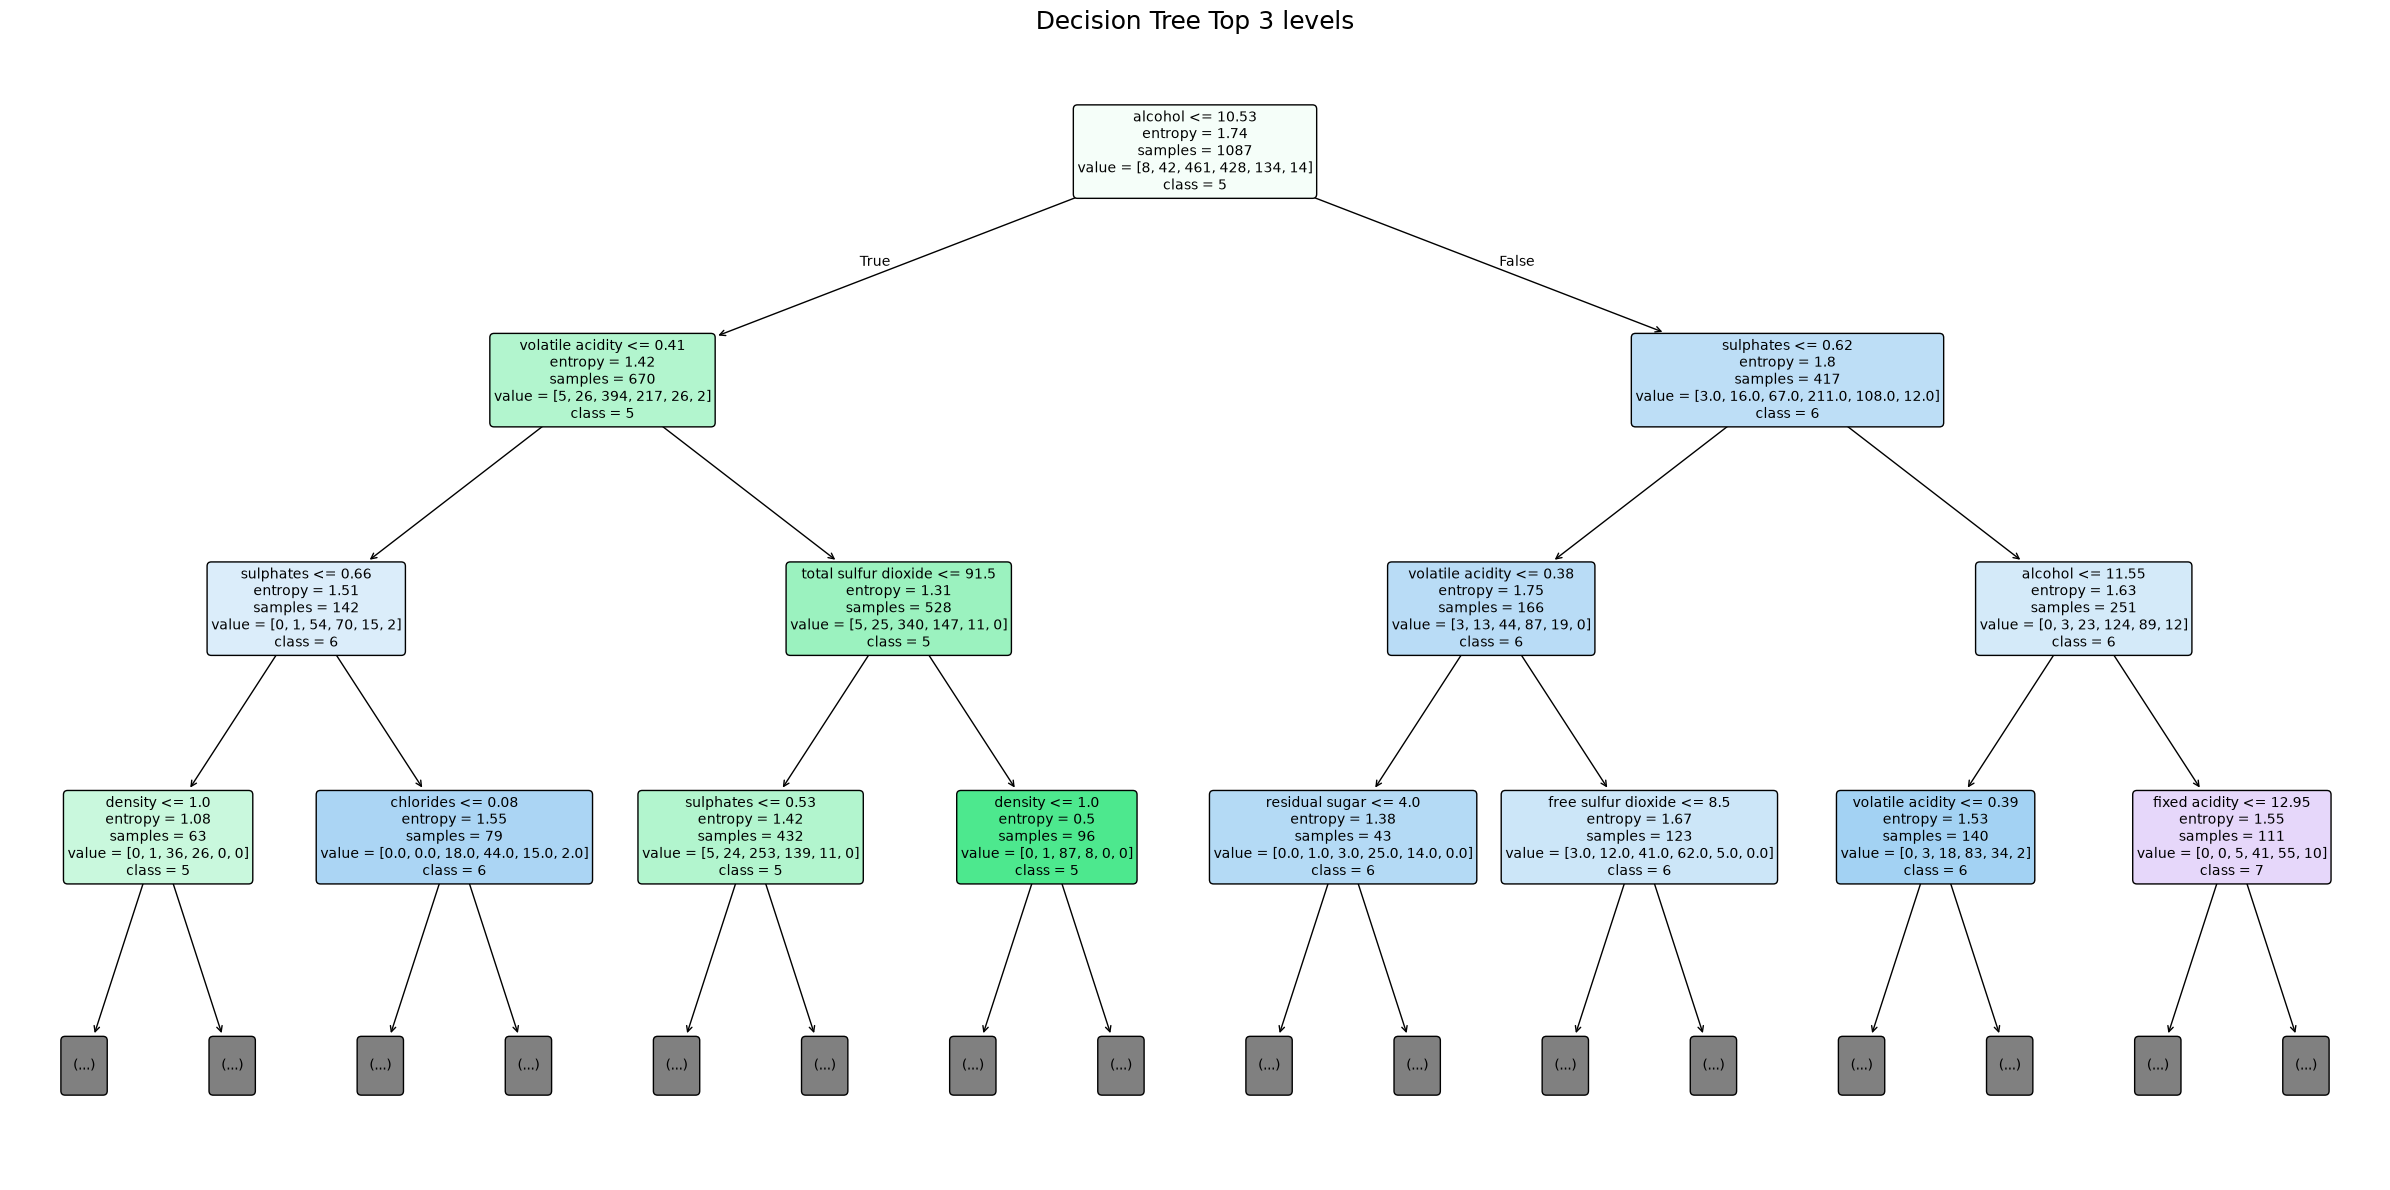

In [45]:
plt.figure(figsize=(24,12))
plot_tree(dt_model,feature_names=X.columns,
          class_names=[str(c) for c in sorted(y.unique())],
          filled=True,rounded=True,
          impurity=True,precision=2,fontsize=10,max_depth=3)

plt.title("Decision Tree Top 3 levels",fontsize=18)
plt.tight_layout()
plt.show()

In [46]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve,auc,roc_auc_score

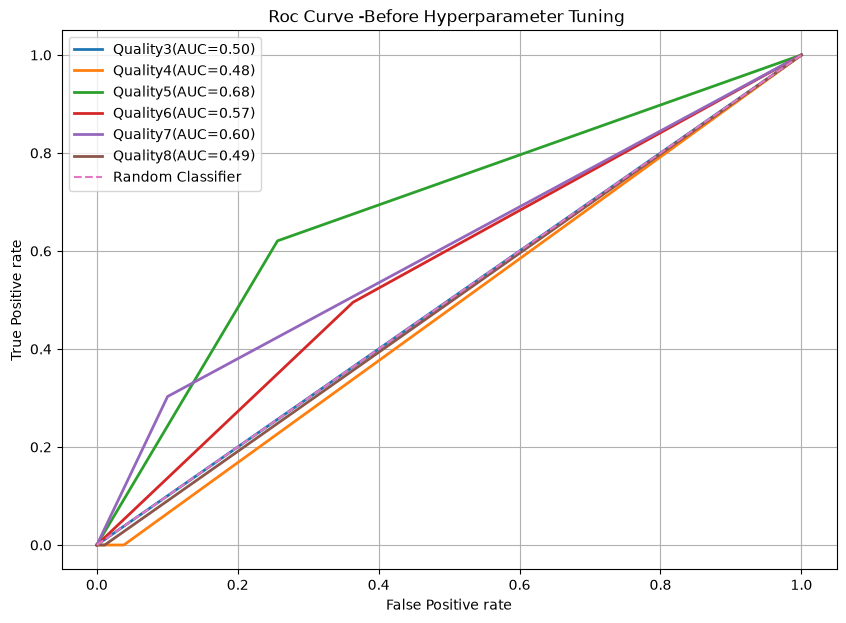

Overall ROC_AUC Before Tuning: 0.615


In [47]:
classes=sorted(y_test.unique())
y_test_bin=label_binarize(y_test,classes=classes)
y_score=dt_model.predict_proba(X_test)
plt.figure(figsize=(10,7))

for i, class_label in enumerate(classes):
    fpr,tpr,thresholds=roc_curve(y_test_bin[:,i],y_score[:,i])
    roc_auc=auc(fpr,tpr)
    plt.plot(fpr,tpr,linewidth=2,label=f'Quality{class_label}(AUC={roc_auc:.2f})')

plt.plot([0,1],[0,1],linestyle='--',label="Random Classifier")

plt.xlabel('False Positive rate')
plt.ylabel('True Positive rate')
plt.title('Roc Curve -Before Hyperparameter Tuning ')

plt.legend()
plt.grid()
plt.show()

overall_auc_before=roc_auc_score(y_test_bin,y_score,multi_class='ovr',average='weighted')
print("Overall ROC_AUC Before Tuning:",round(overall_auc_before,4))

### Hyperparameter Tuning

In [48]:
from sklearn.model_selection import GridSearchCV
import warnings
warnings.filterwarnings('ignore')

param_grid={
    'criterion':['entropy'],
    'max_depth':[3,5,7,10,None],
    'min_samples_split':[2,5,10,20],
    'min_samples_leaf':[1,2,4,8],
    'max_features':[None,'sqrt','log2'],
    'ccp_alpha':[0,0.001,0.005,0.01]
}
grid=GridSearchCV(DecisionTreeClassifier(random_state=42),param_grid,cv=5,scoring='accuracy',n_jobs=-1)
grid.fit(X_train,y_train)
print("Best Parameter")
print(grid.best_params_)
print("Best Cross Validation Accuracy")
print(grid.best_score_)
best_tree=grid.best_estimator_

Best Parameter
{'ccp_alpha': 0.01, 'criterion': 'entropy', 'max_depth': 7, 'max_features': None, 'min_samples_leaf': 8, 'min_samples_split': 20}
Best Cross Validation Accuracy
0.5814399864710607


In [49]:
y_pred=best_tree.predict(X_test)
print(classification_report(y_test,y_pred))
print("Accuracy",accuracy_score(y_test,y_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.63      0.69      0.66       116
           6       0.53      0.54      0.54       107
           7       0.47      0.52      0.49        33
           8       0.00      0.00      0.00         3

    accuracy                           0.57       272
   macro avg       0.27      0.29      0.28       272
weighted avg       0.54      0.57      0.55       272

Accuracy 0.5698529411764706


In [50]:
train_accuracy=best_tree.score(X_train,y_train)
test_accuracy=best_tree.score(X_test,y_test)

print("Training Accuracy:",train_accuracy)
print("Testing Accuracy:",test_accuracy)

Training Accuracy: 0.6209751609935602
Testing Accuracy: 0.5698529411764706


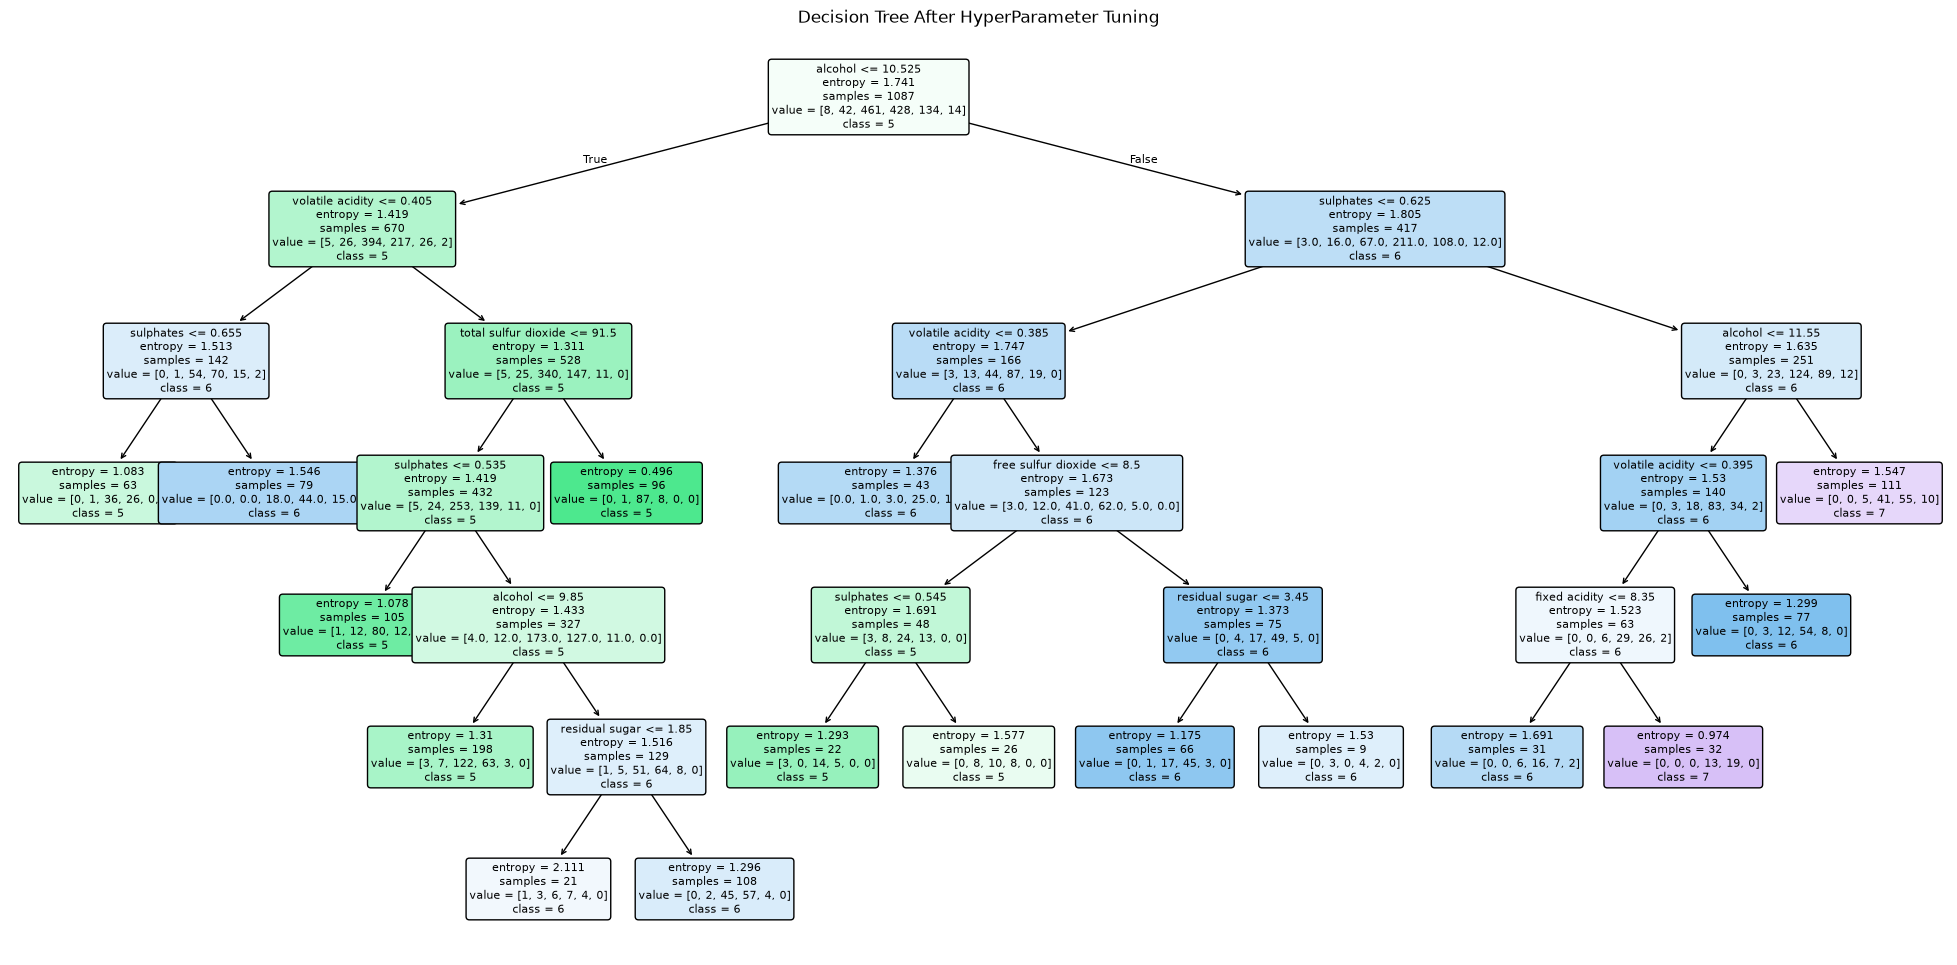

In [51]:
from sklearn.tree import plot_tree

plt.figure(figsize=(25,12))
plot_tree(best_tree,feature_names=X.columns,class_names=[str(c) for c in best_tree.classes_],
filled=True,rounded=True,fontsize=8)
plt.title("Decision Tree After HyperParameter Tuning")
plt.show()

### Cross Validation

In [52]:
from sklearn.model_selection import cross_val_score
scores=cross_val_score(best_tree,X,y,cv=10,scoring='accuracy')
print(scores)
print("Average Accuracy= ",scores.mean())
print("Std= ",scores.std())

[0.46323529 0.60294118 0.61029412 0.5        0.58088235 0.59558824
 0.60294118 0.55147059 0.60294118 0.54814815]
Average Accuracy=  0.5658442265795207
Std=  0.047538408739019426


In [53]:
### learning Curve

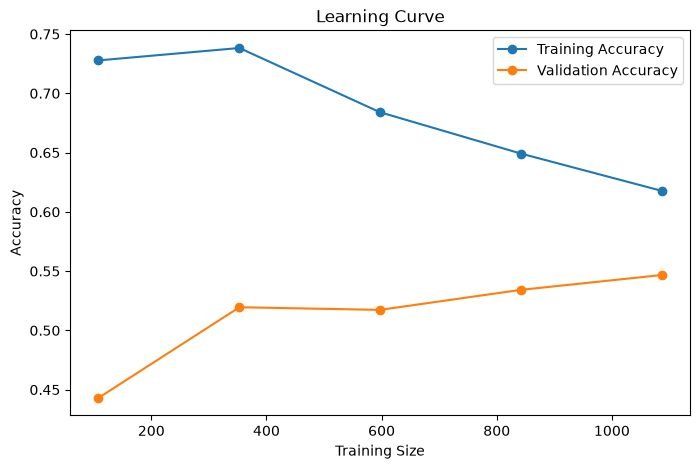

In [54]:
from sklearn.model_selection import learning_curve

train_sizes,train_scores,test_scores=learning_curve(best_tree,X,y,cv=5,scoring='accuracy')
plt.figure(figsize=(8,5))
plt.plot(train_sizes,train_scores.mean(axis=1),marker='o',label='Training Accuracy')
plt.plot(train_sizes,test_scores.mean(axis=1),marker='o',label='Validation Accuracy')

plt.xlabel("Training Size")
plt.ylabel("Accuracy")
plt.title("Learning Curve")

plt.legend()
plt.show()


In [55]:
new_wine = pd.DataFrame([
    {
        'fixed acidity': 7.0,
        'volatile acidity': 0.50,
        'citric acid': 0.20,
        'residual sugar': 2.0,
        'chlorides': 0.070,
        'free sulfur dioxide': 15.0,
        'total sulfur dioxide': 40.0,
        'density': 0.995,
        'pH': 3.30,
        'sulphates': 0.60,
        'alcohol': 10
    }
])
predicted_quality = best_tree.predict(new_wine)
print("Predicted wine quality:", predicted_quality[0])

Predicted wine quality: 6
